In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

housing = pd.read_csv("AmesHousing.csv", sep='\t')

print("First rows of the dataset: ")
display(housing.head())

print(f"\nDimension of the dataset: {housing.shape}")

First rows of the dataset: 


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900



Dimension of the dataset: (2930, 82)


In [2]:
housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  House Style      2930 non

In [3]:
numeric_features = housing.select_dtypes(include=['int64', 'float64']).columns
categorical_features = housing.select_dtypes(include=['object']).columns

print(f"Number of numeric features: {len(numeric_features)}")
print(f"Number of categorical features: {len(categorical_features)}")


Number of numeric features: 39
Number of categorical features: 43


C:\Users\Eu\AppData\Local\Temp\ipykernel_18720\35948791.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = housing.select_dtypes(include=['object']).columns


In [4]:
missing = housing.isna().sum()

# filter the results in order to only keep those that have at least one missing value
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(housing) * 100).round(1)
pd.DataFrame({"fehlend": missing, "Prozent": missing_pct})

,fehlend,Prozent
Pool QC,2917,99.6
Misc Feature,2824,96.4
Alley,2732,93.2
Fence,2358,80.5
Mas Vnr Type,1775,60.6
Fireplace Qu,1422,48.5
Lot Frontage,490,16.7
Garage Qual,159,5.4
Garage Cond,159,5.4
Garage Yr Blt,159,5.4


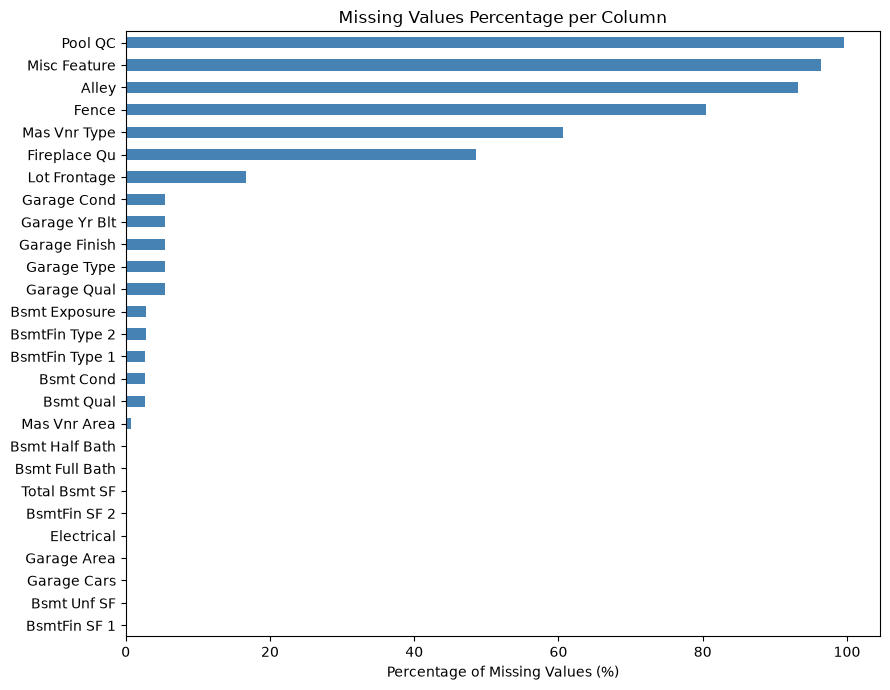

In [5]:
# Horizontal bar chart of missing values percentage
fig, ax = plt.subplots(figsize=(9, 7))
missing_pct.sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("Percentage of Missing Values (%)")
ax.set_title("Missing Values Percentage per Column")
plt.tight_layout()
plt.show()

Interpretation

According to the data description, for Pool QC (99.6%), Misc Feature (96%), Alley (93%), Fence (80%), Fireplace Qu (48%), as well as the Garage and Bsmt columns, NA means "not present" (e.g., no pool, no garage, no basement) and not "value missing". Real missing values are primarily found in Lot Frontage (17%): Every property has a street frontage, so the measurement is truly missing here.

In [6]:
print("Houses without pool:", (housing["Pool Area"] == 0).sum(), "| Pool QC missing:", housing["Pool QC"].isna().sum())
print("Houses without garage:", (housing["Garage Area"] == 0).sum(), "| Garage Type missing:", housing["Garage Type"].isna().sum())

Houses without pool: 2917 | Pool QC missing: 2917
Houses without garage: 157 | Garage Type missing: 157


The numbers match: Where there is no pool or garage, the entry is missing.

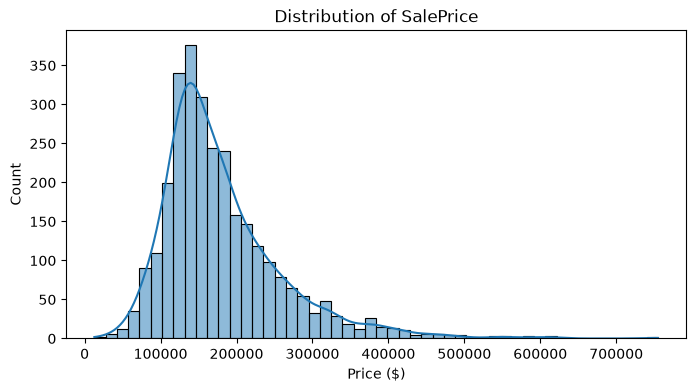

Median: 160000.0 | Maximum: 755000 | Skewness: 1.74


In [7]:
#Histogram – Price distribution
plt.figure(figsize=(8, 4))
sns.histplot(housing["SalePrice"], bins=50, kde=True)
plt.title("Distribution of SalePrice")
plt.xlabel("Price ($)")
plt.show()
print("Median:", housing["SalePrice"].median(), "| Maximum:", housing["SalePrice"].max(), "| Skewness:", round(housing["SalePrice"].skew(), 2))

In [8]:
# the 25th, 50th (median), and 75th percentiles of SalePrice
print(housing["SalePrice"].quantile([0.25, 0.5, 0.75]))

0.25    129500.0
0.50    160000.0
0.75    213500.0
Name: SalePrice, dtype: float64


Interpretation: Most houses cost about $130,000–$215,000 (median $160,000), while few are very expensive (maximum $755,000). The distribution is right-skewed: there aren t many luxury houses.

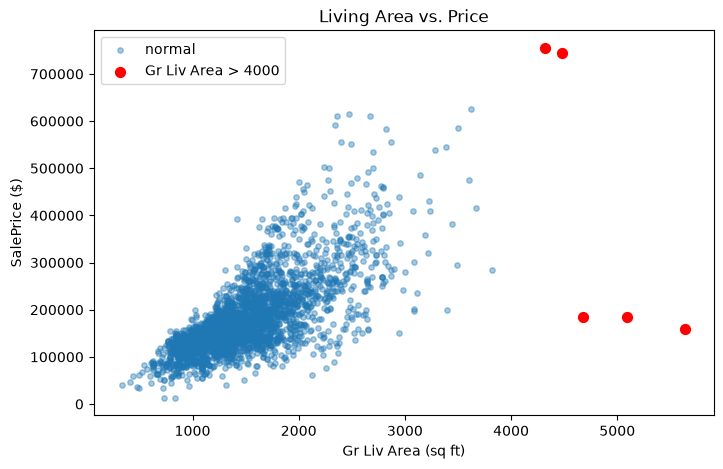

,Gr Liv Area,SalePrice,Sale Condition
1498,5642,160000,Partial
1760,4476,745000,Abnorml
1767,4316,755000,Normal
2180,5095,183850,Partial
2181,4676,184750,Partial


In [9]:
#Scatter Plot – Living Area vs. Price (Outliers in red)
outliers = housing["Gr Liv Area"] > 4000
plt.figure(figsize=(8, 5))
plt.scatter(housing.loc[~outliers, "Gr Liv Area"], housing.loc[~outliers, "SalePrice"], alpha=0.4, s=15, label="normal")
plt.scatter(housing.loc[outliers, "Gr Liv Area"], housing.loc[outliers, "SalePrice"], color="red", s=50, label="Gr Liv Area > 4000")
plt.xlabel("Gr Liv Area (sq ft)")
plt.ylabel("SalePrice ($)")
plt.title("Living Area vs. Price")
plt.legend()
plt.show()

housing.loc[outliers, ["Gr Liv Area", "SalePrice", "Sale Condition"]]

Interpretation: The larger the house, the more expensive it is. Five houses have more than 4,000 sq ft. Three of them (ex, 5,642 sq ft for only $160,000) are sales with Sale Condition = Partial: The house was not yet finished when sold, so the price is not normal. These are outliers.

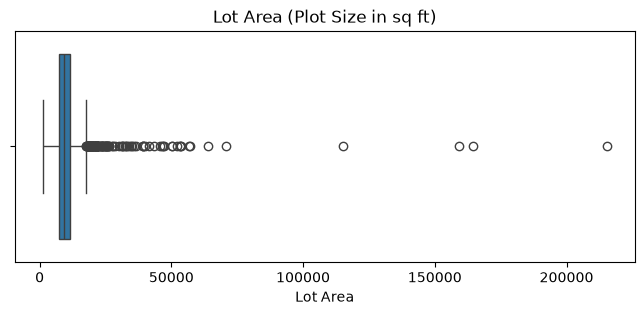

Median: 9436.5 | Maximum: 215245 | Properties > 50000: 14


In [10]:
#Box Plot – Lot Area (Plot Size)
plt.figure(figsize=(8, 3))
sns.boxplot(x=housing["Lot Area"])
plt.title("Lot Area (Plot Size in sq ft)")
plt.show()
print("Median:", housing["Lot Area"].median(), "| Maximum:", housing["Lot Area"].max(), "| Properties > 50000:", (housing["Lot Area"] > 50000).sum())

Interpretation: The median is around 9,400 sq ft, but there are many extremely large properties (up to 215,245 sq ft). These are outliers.

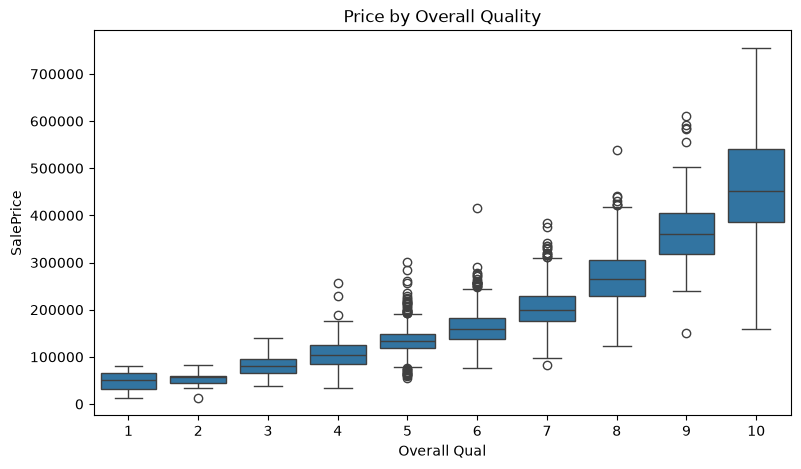

In [11]:
#Box Plot – Price by Overall Quality
plt.figure(figsize=(9, 5))
sns.boxplot(data=housing, x="Overall Qual", y="SalePrice")
plt.title("Price by Overall Quality")
plt.show()

Interpretation: As quality increases, the price rises significantly, and the spread becomes larger. 

In [12]:
correlation_matrix = housing.corr(numeric_only=True)
print(correlation_matrix["SalePrice"].sort_values(ascending=False))

SalePrice          1.000000
Overall Qual       0.799262
Gr Liv Area        0.706780
Garage Cars        0.647877
Garage Area        0.640401
Total Bsmt SF      0.632280
1st Flr SF         0.621676
Year Built         0.558426
Full Bath          0.545604
Year Remod/Add     0.532974
Garage Yr Blt      0.526965
Mas Vnr Area       0.508285
TotRms AbvGrd      0.495474
Fireplaces         0.474558
BsmtFin SF 1       0.432914
Lot Frontage       0.357318
Wood Deck SF       0.327143
Open Porch SF      0.312951
Half Bath          0.285056
Bsmt Full Bath     0.276050
2nd Flr SF         0.269373
Lot Area           0.266549
Bsmt Unf SF        0.182855
Bedroom AbvGr      0.143913
Screen Porch       0.112151
Pool Area          0.068403
Mo Sold            0.035259
3Ssn Porch         0.032225
BsmtFin SF 2       0.005891
Misc Val          -0.015691
Yr Sold           -0.030569
Order             -0.031408
Bsmt Half Bath    -0.035835
Low Qual Fin SF   -0.037660
MS SubClass       -0.085092
Overall Cond      -0

Overall Qual has the highest correlation with the price (0.80).

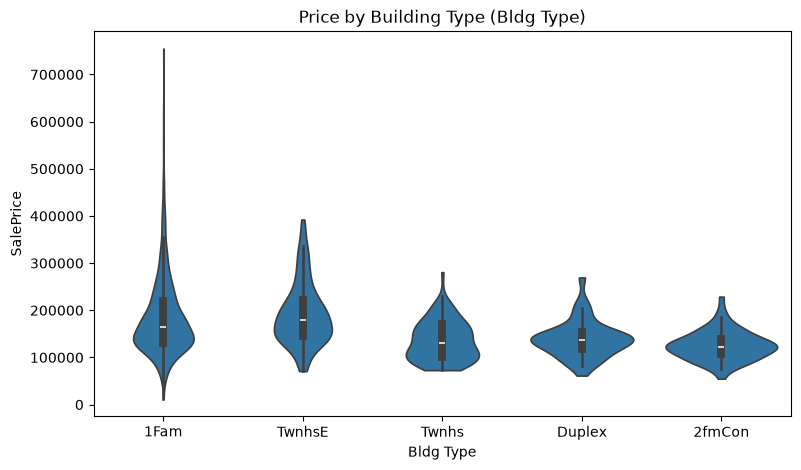

Bldg Type
1Fam      2425
TwnhsE     233
Duplex     109
Twnhs      101
2fmCon      62
Name: count, dtype: int64

In [13]:
# Violin Plot – Price by Building Type
plt.figure(figsize=(9, 5))
sns.violinplot(data=housing, x="Bldg Type", y="SalePrice", cut=0)
plt.title("Price by Building Type (Bldg Type)")
plt.show()
housing["Bldg Type"].value_counts()

Interpretation: Most houses (2,425 out of 2,930) are single-family detached houses (1Fam) with a very wide price distribution. End-unit townhouses (TwnhsE) have a higher median price than mid-unit townhouses (Twnhs); 2fmCon and Duplex are the least expensive.

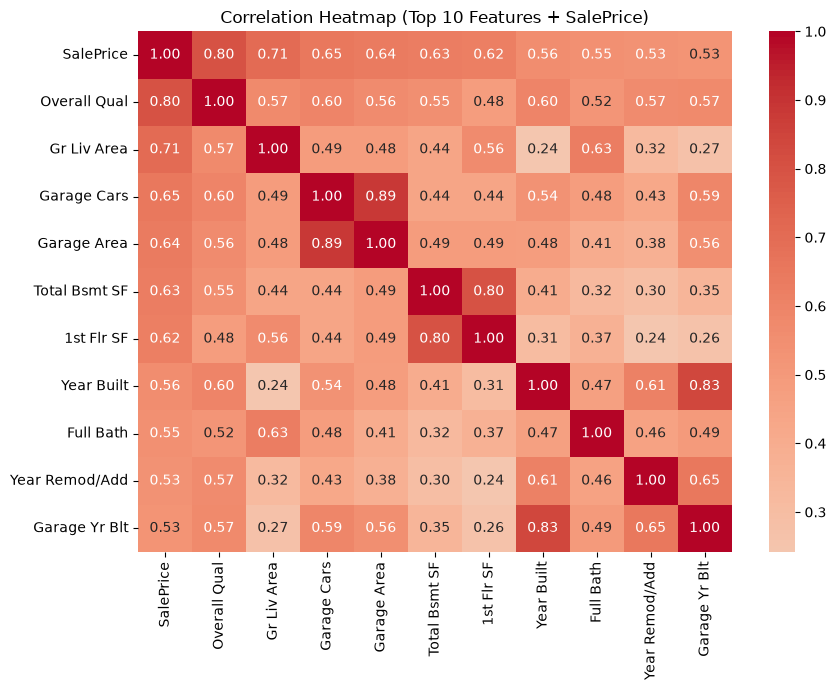

In [14]:
# Heatmap – Correlations of the Most Important Numerical Features
top = housing[numeric_features].corr()["SalePrice"].abs().sort_values(ascending=False).head(11).index
plt.figure(figsize=(9, 7))
sns.heatmap(housing[top].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Top 10 Features + SalePrice)")
plt.tight_layout()
plt.show()

Interpretation: The features with the strongest correlation to the price are Overall Qual (0.80), Gr Liv Area (0.71), Garage Cars (0.65), Garage Area (0.64), Total Bsmt SF (0.63), and 1st Flr SF (0.62). Some features are also strongly correlated with each other, e.g., Garage Cars and Garage Area (0.89).

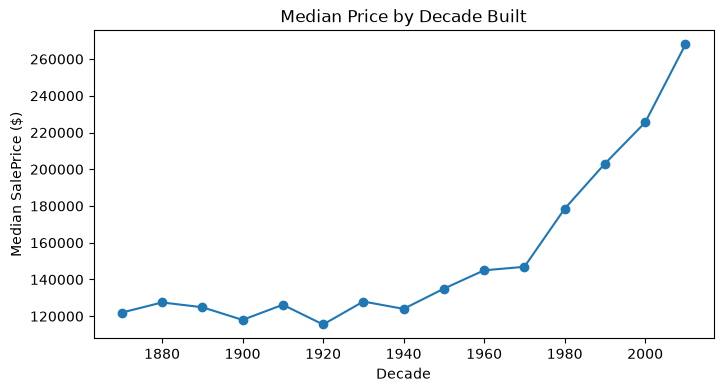

In [15]:
# Line Plot – Median Price by Decade Built
housing["Decade"] = housing["Year Built"] // 10 * 10
housing.groupby("Decade")["SalePrice"].median().plot(marker="o", figsize=(8, 4))
plt.ylabel("Median SalePrice ($)")
plt.title("Median Price by Decade Built")
plt.show()

Interpretation: Up to about 1940, the median price remains aproximately the same ($115,000–$128,000), after which prices for newer houses rise significantly (around $225,000 for houses from the 2000s). Therefore, the relationship between year and price is not linear.

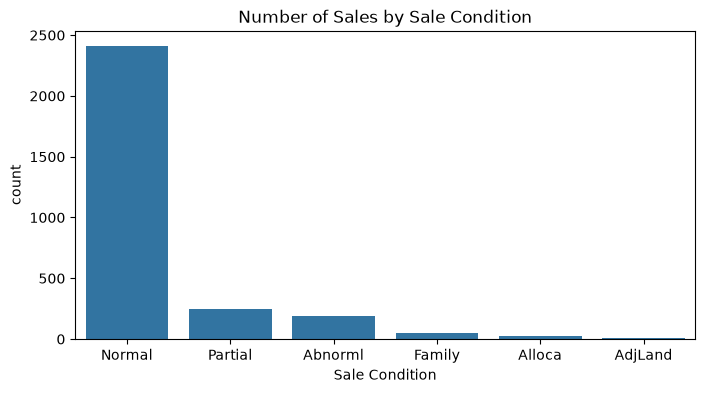

Sale Condition
Normal     0.824
Partial    0.084
Abnorml    0.065
Family     0.016
Alloca     0.008
AdjLand    0.004
Name: proportion, dtype: float64

In [16]:
#Count Plot – Number of Sales by Sale Condition
plt.figure(figsize=(8, 4))
sns.countplot(data=housing, x="Sale Condition", order=housing["Sale Condition"].value_counts().index)
plt.title("Number of Sales by Sale Condition")
plt.show()
housing["Sale Condition"].value_counts(normalize=True).round(3)

Interpretation: 82% of sales are normal (Normal). The other categories (e.g., Partial, Abnorml) are special cases whose prices do not reflect the standard market.

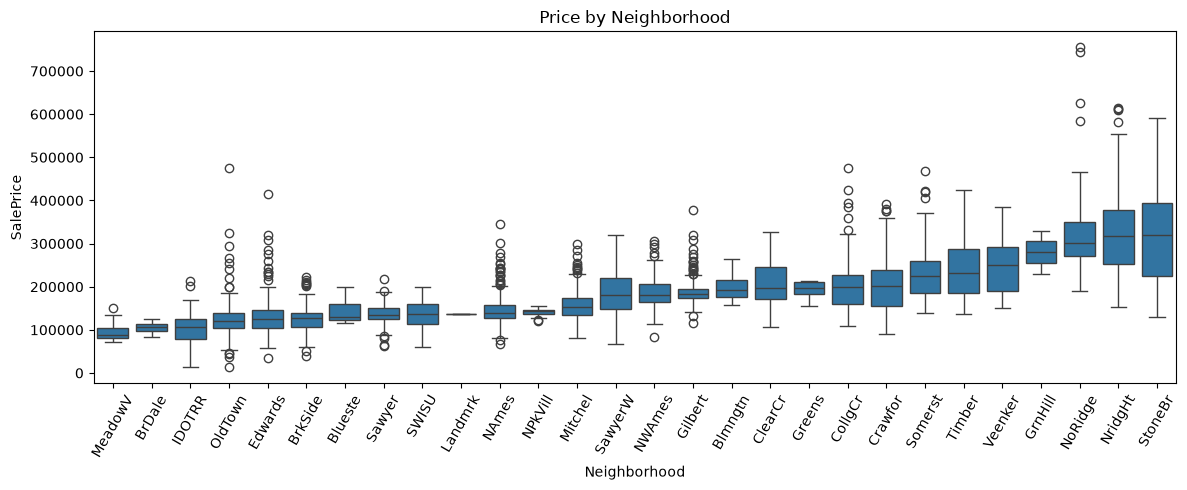

In [17]:
#Box Plot – Preis by Neighborhood
order = housing.groupby("Neighborhood")["SalePrice"].median().sort_values().index
plt.figure(figsize=(12, 5))
sns.boxplot(data=housing, x="Neighborhood", y="SalePrice", order=order)
plt.xticks(rotation=60)
plt.title("Price by Neighborhood")
plt.tight_layout()
plt.show()

In [18]:
mediane_specifice = housing[housing["Neighborhood"].isin(["MeadowV", "StoneBr"])].groupby("Neighborhood")["SalePrice"].median()
print(mediane_specifice)

Neighborhood
MeadowV     88250.0
StoneBr    319000.0
Name: SalePrice, dtype: float64


Interpretation: Location matters: The median price ranges from about $88,000 (MeadowV) to about $319,000 (StoneBr).

## With what external data could the dataset be enriched? / Mit was für Daten von außen könnte man das Dataset bereichern?

-  **Interest rates and inflation at the time of sale (Yr Sold, Mo Sold)**: They influence how much buyers can afford.

- **Neighborhood data (income, crime rate, population density)**: Neighborhood only gives the name, not how "good" the area is.

- **Distances to schools, university, city center, highway**: Location strongly affects the price, but the dataset does not contain exact locations.



## Which features are candidates for removal? / Welche vorhandenen Features kann man als Kandidaten für Entfernung sehen?
- `Order, PID`: just identifiers, not a property of the house.

- `Pool QC, Misc Feature, Alley`: over 90% missing, almost no information.

- `Garage Cars` or Garage Area: correlation 0.89, redundant (one is enough).

- `Garage Yr Blt`: correlation 0.83 with `Year Built`, 159 fehlende Werte

## What additional meaningful features can be created from combinations of the given features? Was für zusätzliche sinnvolle Features kann man aus Kombinationen der gegebenen Features erzeugen

In [19]:
h = housing.copy()
for c in ["Total Bsmt SF", "Bsmt Full Bath", "Bsmt Half Bath"]:
    h[c] = h[c].fillna(0)

h["TotalSF"]   = h["Total Bsmt SF"] + h["1st Flr SF"] + h["2nd Flr SF"]
h["HouseAge"]  = h["Yr Sold"] - h["Year Built"]
h["TotalBath"] = h["Full Bath"] + 0.5 * h["Half Bath"] + h["Bsmt Full Bath"] + 0.5 * h["Bsmt Half Bath"]

h[["TotalSF", "HouseAge", "TotalBath"]].corrwith(h["SalePrice"]).round(2)

TotalSF      0.79
HouseAge    -0.56
TotalBath    0.64
dtype: float64

- **TotalSF** (Basement + 1st + 2nd Floor): The correlation with the price (0.79) is higher than that of Gr Liv Area (0.71).   
- **HouseAge** (Year Sold – Year Built): The age at the time of sale is more meaningful than the raw construction year. Newer houses are more expensive (correlation –0.56).   

- **TotalBath**: Combines four bathroom columns (full/half, upper floor/basement) into a single number (half bath = 0.5). Correlation is 0.64.      